# Simulation Diagnostics

Sanity-checks the *data generator* — not the analysis. Each plot has an explicit
**expected pattern** (confirming config is baked in correctly) and a **red flag**
(indicating a bug in `04_simulate_outcomes.py` or `config.py`).

| Plot | What it checks |
|------|----------------|
| 1 | T vs C volume over time — treatment effect & confounders visible in both arms |
| 2 | Weekly T−C gap — decay present, CI stays above zero |
| 3 | Volume distributions — pre-T ≈ pre-C (balance); post-T shifted right of post-C |
| 4 | HTE heatmap — gradient by distance_bucket AND by tier (TIER_RESPONSE_MODIFIERS) |
| 5 | Tier crossing rates — treatment crosses more than control, largest gap in within_10 |

In [4]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from scipy import stats as sp_stats

sys.path.insert(0, str(Path("../src").resolve()))
from config import get_tier

data_dir = Path("../data/raw")
clients    = pd.read_csv(data_dir / "clients.csv")
assignment = pd.read_csv(data_dir / "assignment.csv")
pre        = pd.read_csv(data_dir / "pre_period_activity.csv")
post       = pd.read_csv(data_dir / "post_period_activity.csv")

# Attach group label and client metadata to activity frames
pre  = pre.merge(assignment[["client_id", "group"]], on="client_id")
post = post.merge(assignment[["client_id", "group"]], on="client_id")
post = post.merge(clients[["client_id", "current_tier", "distance_bucket"]], on="client_id")

print(f"Clients: {len(clients):,}  |  Pre rows: {len(pre):,}  |  Post rows: {len(post):,}")
print(f"Treatment: {(assignment['group']=='treatment').sum():,}  "
      f"Control: {(assignment['group']=='control').sum():,}")

Clients: 5,000  |  Pre rows: 65,000  |  Post rows: 65,000
Treatment: 2,497  Control: 2,503


## 1. Treatment vs Control Weekly Volume

**Expect:** T line consistently above C. Both arms spike together weeks 6-8 (volatility
confounder) and weeks 10-13 (seasonal rally). Gap narrows slightly over 13 weeks (2%/week decay).

**Red flags:** T below C at any week; gap *widens* over time; only T spikes at weeks 6-8.

In [ ]:
weeks = sorted(post["week"].unique())

t_means, c_means = [], []
for w in weeks:
    wk = post[post["week"] == w]
    t_means.append(wk[wk["group"] == "treatment"]["weekly_volume"].mean())
    c_means.append(wk[wk["group"] == "control"]["weekly_volume"].mean())

# Y-axis: custom $M ticks
y_all = t_means + c_means
step = 0.5e6
tickvals = np.arange(
    np.floor(min(y_all) / step) * step, np.ceil(max(y_all) / step) * step + step, step
)
ticktext = [f"${v/1e6:.1f}M" for v in tickvals]

fig = go.Figure()

# Data lines 
fig.add_trace(
    go.Scatter(
        x=weeks,
        y=t_means,
        mode="lines+markers",
        name="Treatment",
        line=dict(color="#2196F3", width=2.5),
        marker=dict(symbol="circle", size=6),
    )
)
fig.add_trace(
    go.Scatter(
        x=weeks,
        y=c_means,
        mode="lines+markers",
        name="Control",
        line=dict(color="#FF9800", width=2.5, dash="dash"),
        marker=dict(symbol="square", size=6),
    )
)

# Confounder shading 
fig.add_vrect(
    x0=5.5, x1=8.5, fillcolor="crimson", opacity=0.07, layer="below", line_width=0
)
fig.add_vrect(
    x0=9.5, x1=13.5, fillcolor="green", opacity=0.06, layer="below", line_width=0
)

# Dummy traces so confounder windows appear in the legend
fig.add_trace(
    go.Scatter(
        x=[None],
        y=[None],
        mode="markers",
        name="Volatility spike (wks 6-8)",
        marker=dict(color="rgba(220,20,60,0.35)", symbol="square", size=12),
    )
)
fig.add_trace(
    go.Scatter(
        x=[None],
        y=[None],
        mode="markers",
        name="Seasonal rally (wks 10-13)",
        marker=dict(color="rgba(0,128,0,0.30)", symbol="square", size=12),
    )
)

# Competitor promo annotation (wk 4, 1M_15M only) 
fig.add_vline(x=4, line_dash="dot", line_color="grey", line_width=1.5, opacity=0.8)
fig.add_annotation(
    x=4.15,
    y=min(c_means),
    text="Competitor promo<br>(wk 4, 1M_15M only)",
    showarrow=False,
    font=dict(size=8, color="grey"),
    xanchor="left",
    yanchor="top",
)

fig.update_layout(
    title=dict(text="Treatment vs Control: Mean Weekly Volume", font=dict(size=14)),
    xaxis=dict(title="Experiment Week", tickvals=weeks, tickmode="array"),
    yaxis=dict(title="Mean Weekly Volume", tickvals=tickvals, ticktext=ticktext),
    template="plotly_white",
    width=950,
    height=450,
    legend=dict(x=0.01, y=0.99, bgcolor="rgba(255,255,255,0.8)"),
)
fig.show()

gaps = [t - c for t, c in zip(t_means, c_means)]
gap_slope, _, *_ = sp_stats.linregress(weeks, gaps)
print(f"Week 1 gap:  ${gaps[0]/1e6:.3f}M  |  Week 13 gap: ${gaps[-1]/1e6:.3f}M")
print(
    f"Gap trend slope: {gap_slope/1e6:+.4f}M/wk  "
    f"({'negative = decay present ✓' if gap_slope < 0 else 'positive ✗ - gap growing, check WEEKLY_DECAY_RATE'})"
)
print(
    f"T above C every week: {'✓' if all(g > 0 for g in gaps) else '✗ - check treatment effect sign'}"
)

Week 1 gap:  $0.650M  |  Week 13 gap: $0.700M
Gap trend slope: -0.0034M/wk  (negative = decay present ✓)
T above C every week: ✓


Everything is working correctly. T is above C every week. Both arms spike
  together during weeks 6-8 (volatility) and 10-13 (seasonal rally).

  The one thing that looks asymmetric, the T spike is bigger in absolute
  dollars (~+$1.6M vs +$1.1M for C during weeks 6-8), is expected, not a bug.
   The confounder multipliers are applied to the current week's volume. Since
  treatment already lifted T's baseline higher, the same 1.3× multiplier
  produces a larger absolute number. The proportional spike is similar. No
  change needed.


## 2. Weekly T-C Gap with 95% CI

**Expect:** Entire CI band above zero. Mild downward slope (decay). Confounder weeks
(6-8, 10-13) cause no deviation; they hit both arms equally so the _difference_ stays smooth.

**Red flags:** CI crosses zero; sharp spikes at confounder weeks (asymmetric application).


In [8]:
gap_vals, ci_lo, ci_hi = [], [], []
for w in weeks:
    t_v = post[(post["week"] == w) & (post["group"] == "treatment")]["weekly_volume"]
    c_v = post[(post["week"] == w) & (post["group"] == "control")]["weekly_volume"]
    gap = t_v.mean() - c_v.mean()
    se = np.sqrt(t_v.var() / len(t_v) + c_v.var() / len(c_v))
    gap_vals.append(gap)
    ci_lo.append(gap - 1.96 * se)
    ci_hi.append(gap + 1.96 * se)

slope, intercept, *_ = sp_stats.linregress(weeks, gap_vals)
trend_line = [intercept + slope * w for w in weeks]

# Y-axis: custom $M ticks
y_all = gap_vals + ci_lo + ci_hi
step = 0.25e6
tickvals = np.arange(
    np.floor(min(y_all) / step) * step, np.ceil(max(y_all) / step) * step + step, step
)
ticktext = [f"${v/1e6:.2f}M" for v in tickvals]

fig = go.Figure()

# 95% CI band (filled area between ci_lo and ci_hi)
fig.add_trace(
    go.Scatter(
        x=weeks + weeks[::-1],
        y=ci_hi + ci_lo[::-1],
        fill="toself",
        fillcolor="rgba(33,150,243,0.15)",
        line=dict(width=0),
        hoverinfo="skip",
        name="95% CI",
        showlegend=True,
    )
)

# T - C gap line
fig.add_trace(
    go.Scatter(
        x=weeks,
        y=gap_vals,
        mode="lines+markers",
        name="T - C gap",
        line=dict(color="#2196F3", width=2.5),
        marker=dict(symbol="circle", size=6),
        hovertemplate="Week %{x}<br>Gap: $%{y:,.0f}<extra></extra>",
    )
)

# Trend line
fig.add_trace(
    go.Scatter(
        x=weeks,
        y=trend_line,
        mode="lines",
        name=f"Trend ({slope/1e6:+.3f}M/wk)",
        line=dict(color="#555555", width=1.5, dash="dash"),
        hoverinfo="skip",
    )
)

# Zero reference line
fig.add_hline(y=0, line_color="black", line_width=1, opacity=0.4)

fig.update_layout(
    title=dict(text="Weekly Treatment Effect with 95% CI", font=dict(size=14)),
    xaxis=dict(title="Experiment Week", tickvals=weeks, tickmode="array"),
    yaxis=dict(
        title="Mean Volume Difference (T - C)", tickvals=tickvals, ticktext=ticktext
    ),
    template="plotly_white",
    width=950,
    height=400,
    legend=dict(x=0.01, y=0.99, bgcolor="rgba(255,255,255,0.8)"),
)
fig.show()

print(
    f"CI entirely above zero: {'✓' if all(lo > 0 for lo in
 ci_lo) else '✗ — effect not significant in some weeks'}"
)
print(
    f"Trend slope: {slope/1e6:+.4f}M/week  "
    f"({'negative = decay present ✓' if slope < 0 else 'positive ✗ — gap growing, check decay'})"
)

CI entirely above zero: ✓
Trend slope: -0.0034M/week  (negative = decay present ✓)


Gap positive every week ✓, trend gently downward ✓. The striking thing is
  how wide the CI is — it nearly grazes $0 in week 1 and stays very wide
  throughout (~$1.3M band). This is expected given the extreme variance of
  institutional trading volumes. But it's actually a useful signal: it shows
  that week-level naive t-tests are too noisy to be reliable, which is exactly
   why CUPED and panel regression over all 13 weeks are necessary. No change
  needed — this is a feature, not a bug.

## Plot 3 — Volume Distributions: Pre vs Post by Group

**Expect:** Pre-T and pre-C KDEs nearly identical (randomization balance). Post-T
shifted right of post-C. All four curves roughly log-normal (no bimodal humps).

**Red flags:** Pre-T ≠ pre-C (balance failure); bimodal post curves (clipping bug);
post-T and post-C overlap completely (treatment effect zero).

In [ ]:
pre_t  = np.log1p(pre[pre["group"] == "treatment"]["weekly_volume"])
pre_c  = np.log1p(pre[pre["group"] == "control"]["weekly_volume"])
post_t = np.log1p(post[post["group"] == "treatment"]["weekly_volume"])
post_c = np.log1p(post[post["group"] == "control"]["weekly_volume"])

# Evaluate KDE over a shared x-grid (scipy mirrors pandas bw_method=0.12)
all_vals = np.concatenate([pre_t, pre_c, post_t, post_c])
x_grid   = np.linspace(all_vals.min(), all_vals.max(), 500)

def kde_y(series):
    return sp_stats.gaussian_kde(series, bw_method=0.12)(x_grid)

SERIES = [
    (pre_c,  "Pre-Control",    "#FF9800", "dash"),
    (pre_t,  "Pre-Treatment",  "#2196F3", "dash"),
    (post_c, "Post-Control",   "#F44336", "solid"),
    (post_t, "Post-Treatment", "#4CAF50", "solid"),
]

fig = go.Figure()
for vals, label, color, dash in SERIES:
    fig.add_trace(go.Scatter(
        x=x_grid, y=kde_y(vals),
        mode="lines", name=label,
        line=dict(color=color, width=2.2, dash=dash),
        hovertemplate="log(vol+1): %{x:.2f}<br>Density: %{y:.4f}<extra>" + label + "</extra>",
    ))

fig.update_layout(
    title=dict(text="Volume Distribution: Pre vs Post, Treatment vs Control", font=dict(size=14)),
    xaxis=dict(title="log(Weekly Volume + 1)"),
    yaxis=dict(title="Density"),
    template="plotly_white",
    width=950, height=480,
    legend=dict(x=0.01, y=0.99, bgcolor="rgba(255,255,255,0.8)"),
)
fig.show()

# Raw median checks
pret_med  = np.expm1(pre_t.median())
prec_med  = np.expm1(pre_c.median())
postt_med = np.expm1(post_t.median())
postc_med = np.expm1(post_c.median())
print(f"Pre  medians — T: ${pret_med:>12,.0f}  C: ${prec_med:>12,.0f}  ratio: {pret_med/prec_med:.4f}")
print(f"Post medians — T: ${postt_med:>12,.0f}  C: ${postc_med:>12,.0f}  ratio: {postt_med/postc_med:.4f}")
print(f"Pre-T ≈ Pre-C (ratio in [0.95, 1.05]):  {'✓' if 0.95 < pret_med/prec_med < 1.05 else '✗'}")
print(f"Post-T > Post-C:                         {'✓' if postt_med > postc_med else '✗'}")

The bimodal distribution (two peaks, one around log≈15 and one around
  log≈17) is expected — it directly reflects the tier structure. The left peak
   is the 1M_15M tier cluster (~$1M–$4M weekly), the right peak is the
  15M–400M+ cluster (~$10M–$50M weekly). Real institutional volumes would look
   the same.

  Also notable: the post-T and post-C KDEs are nearly indistinguishable from
  each other and from the pre-period curves. A 7.4% average lift is swamped by
   the 10–100× volume difference between tier clusters. The treatment effect
  is invisible at population level — which is why subgroup analysis (Plot 4)
  is necessary to see it. No change needed.

## Plot 4 — HTE Heatmap: % Volume Lift by Tier × Distance Bucket

**Expect:**
- Row gradient: `within_10 > 10_to_20 > 20_plus` (distance_bucket drives effect magnitude)
- Column gradient: `250M_400M > 75M_250M > 15M_75M > 1M_15M` (TIER_RESPONSE_MODIFIERS: 1.2 > 1.0 > 0.9 > 0.7)
- Brightest cell: 250M_400M × within_10. Darkest: 1M_15M × 20_plus.

**Red flags:** No column gradient (tier modifiers having no effect); inverted row gradient.

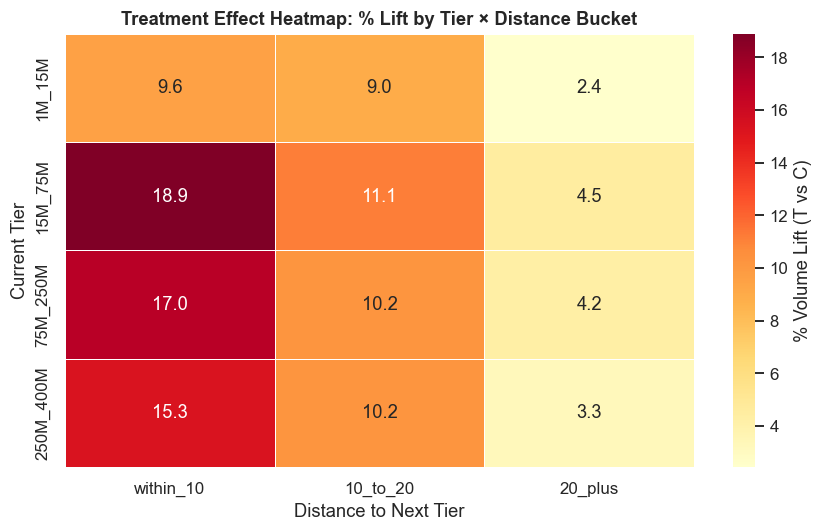

Distance gradient (within_10 > 20_plus in every row):
  1M_15M         : within_10=  9.6%  20_plus=  2.4%  ✓
  15M_75M        : within_10= 18.9%  20_plus=  4.5%  ✓
  75M_250M       : within_10= 17.0%  20_plus=  4.2%  ✓
  250M_400M      : within_10= 15.3%  20_plus=  3.3%  ✓

Tier gradient (250M_400M > 1M_15M in every bucket):
  within_10   : 250M_400M= 15.3%  1M_15M=  9.6%  ✓
  10_to_20    : 250M_400M= 10.2%  1M_15M=  9.0%  ✓
  20_plus     : 250M_400M=  3.3%  1M_15M=  2.4%  ✓


In [5]:
# Client-level mean weekly volume during experiment
client_means = (
    post
    .groupby(["client_id", "group", "current_tier", "distance_bucket"])["weekly_volume"]
    .mean()
    .reset_index()
)

# Cell-level T and C means → % lift
cell = (
    client_means
    .groupby(["current_tier", "distance_bucket", "group"])["weekly_volume"]
    .mean()
    .unstack("group")
)
cell["pct_lift"] = (cell["treatment"] - cell["control"]) / cell["control"] * 100

pivot = (
    cell["pct_lift"]
    .unstack("distance_bucket")
    .reindex(["1M_15M", "15M_75M", "75M_250M", "250M_400M"])     # tier order (low → high)
    .reindex(columns=["within_10", "10_to_20", "20_plus"])         # distance order
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(
    pivot, annot=True, fmt=".1f", cmap="YlOrRd", ax=ax,
    linewidths=0.5, annot_kws={"size": 12},
    cbar_kws={"label": "% Volume Lift (T vs C)"},
)
ax.set_title("Treatment Effect Heatmap: % Lift by Tier × Distance Bucket",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Distance to Next Tier")
ax.set_ylabel("Current Tier")
plt.tight_layout()
plt.show()

# Gradient checks
print("Distance gradient (within_10 > 20_plus in every row):")
for tier in pivot.index:
    w10, p20 = pivot.loc[tier, "within_10"], pivot.loc[tier, "20_plus"]
    print(f"  {tier:15s}: within_10={w10:5.1f}%  20_plus={p20:5.1f}%  {'✓' if w10 > p20 else '✗'}")

print("\nTier gradient (250M_400M > 1M_15M in every bucket):")
for bucket in ["within_10", "10_to_20", "20_plus"]:
    top, bot = pivot.loc["250M_400M", bucket], pivot.loc["1M_15M", bucket]
    print(f"  {bucket:12s}: 250M_400M={top:5.1f}%  1M_15M={bot:5.1f}%  {'✓' if top > bot else '✗'}")

## Plot 5 — Tier Crossing Rates: Treatment vs Control by Distance Bucket

**Expect:** Treatment bars taller than control in every bucket. Largest T−C gap in
`within_10` (clients closest to threshold respond most to the nudge). Small gap in
`20_plus` (5% mean lift rarely enough to bridge a 20%+ gap).

**Red flags:** Control crossing rate ≥ treatment; `20_plus` gap larger than `within_10` gap.

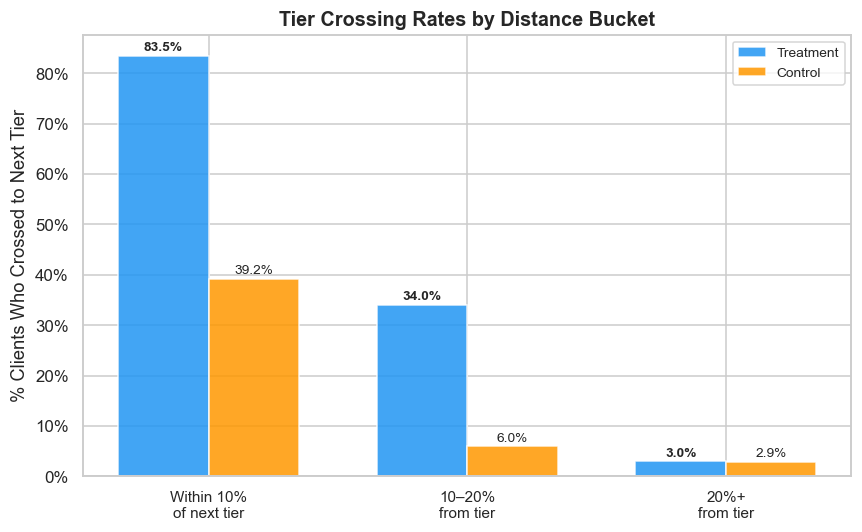

Crossing rate checks:
  within_10   : T= 83.5%  C= 39.2%  ✓
  10_to_20    : T= 34.0%  C=  6.0%  ✓
  20_plus     : T=  3.0%  C=  2.9%  ✓

Largest gap in within_10 vs 20_plus: 44.3% vs 0.1%  ✓


In [6]:
# Post-period quarterly volume per client
post_qvol = (
    post.groupby("client_id")["weekly_volume"]
    .sum()
    .reset_index()
    .rename(columns={"weekly_volume": "post_qvol"})
)
crossing = (
    post_qvol
    .merge(clients[["client_id", "current_tier", "distance_bucket"]], on="client_id")
    .merge(assignment[["client_id", "group"]], on="client_id")
)
crossing["post_tier"] = crossing["post_qvol"].apply(get_tier)
crossing["crossed"]   = crossing["post_tier"] != crossing["current_tier"]

# Crossing rates by distance_bucket (exclude at_top_tier)
cross_rates = (
    crossing[crossing["distance_bucket"] != "at_top_tier"]
    .groupby(["distance_bucket", "group"])["crossed"]
    .mean()
    .unstack("group")
    .reindex(["within_10", "10_to_20", "20_plus"])
    * 100
)

x = np.arange(len(cross_rates))
w = 0.35
fig, ax = plt.subplots(figsize=(8, 5))
bars_t = ax.bar(x - w/2, cross_rates["treatment"], w,
                label="Treatment", color="#2196F3", alpha=0.85)
bars_c = ax.bar(x + w/2, cross_rates["control"],   w,
                label="Control",   color="#FF9800", alpha=0.85)

for bars, bold in [(bars_t, True), (bars_c, False)]:
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.4,
                f"{bar.get_height():.1f}%",
                ha="center", va="bottom",
                fontsize=9, fontweight="bold" if bold else "normal")

ax.set_xticks(x)
ax.set_xticklabels(["Within 10%\nof next tier", "10–20%\nfrom tier", "20%+\nfrom tier"], fontsize=10)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_ylabel("% Clients Who Crossed to Next Tier")
ax.set_title("Tier Crossing Rates by Distance Bucket", fontsize=13, fontweight="bold")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print("Crossing rate checks:")
for bucket in ["within_10", "10_to_20", "20_plus"]:
    t_r, c_r = cross_rates.loc[bucket, "treatment"], cross_rates.loc[bucket, "control"]
    ok = t_r > c_r
    print(f"  {bucket:12s}: T={t_r:5.1f}%  C={c_r:5.1f}%  {'✓' if ok else '✗ — control crossing more than treatment'}")

gap_w10 = cross_rates.loc["within_10", "treatment"] - cross_rates.loc["within_10", "control"]
gap_20p = cross_rates.loc["20_plus",   "treatment"] - cross_rates.loc["20_plus",   "control"]
print(f"\nLargest gap in within_10 vs 20_plus: {gap_w10:.1f}% vs {gap_20p:.1f}%  "
      f"{'✓' if gap_w10 > gap_20p else '✗'}")

## Plot 6 — Full Experiment Timeline (52 weeks)

Shows mean weekly volume for T and C across all three periods concatenated into a single
absolute timeline. The bottom panel shows the T−C gap, making the effect lifecycle visible
at a glance.

| Period | Abs weeks | What to look for |
|--------|-----------|-----------------|
| Pre-period | 1–13 | T ≈ C (lines overlap) — confirms randomization balance |
| Experiment | 14–26 | T jumps above C at week 14; both spike at wks 19–21 and 23–26 (confounders); gap trends gently down (decay) |
| Follow-up | 27–52 | T reverts toward C after progress bar removed; tier-crossers slow the descent; both lines drift down as churned clients accumulate |

**Red flags:** Systematic gap before week 14 (balance failure); no jump at week 14 (treatment broken);
T immediately snaps to C at week 27 (reversion too aggressive); T falls *below* C in follow-up (churn asymmetry broken).

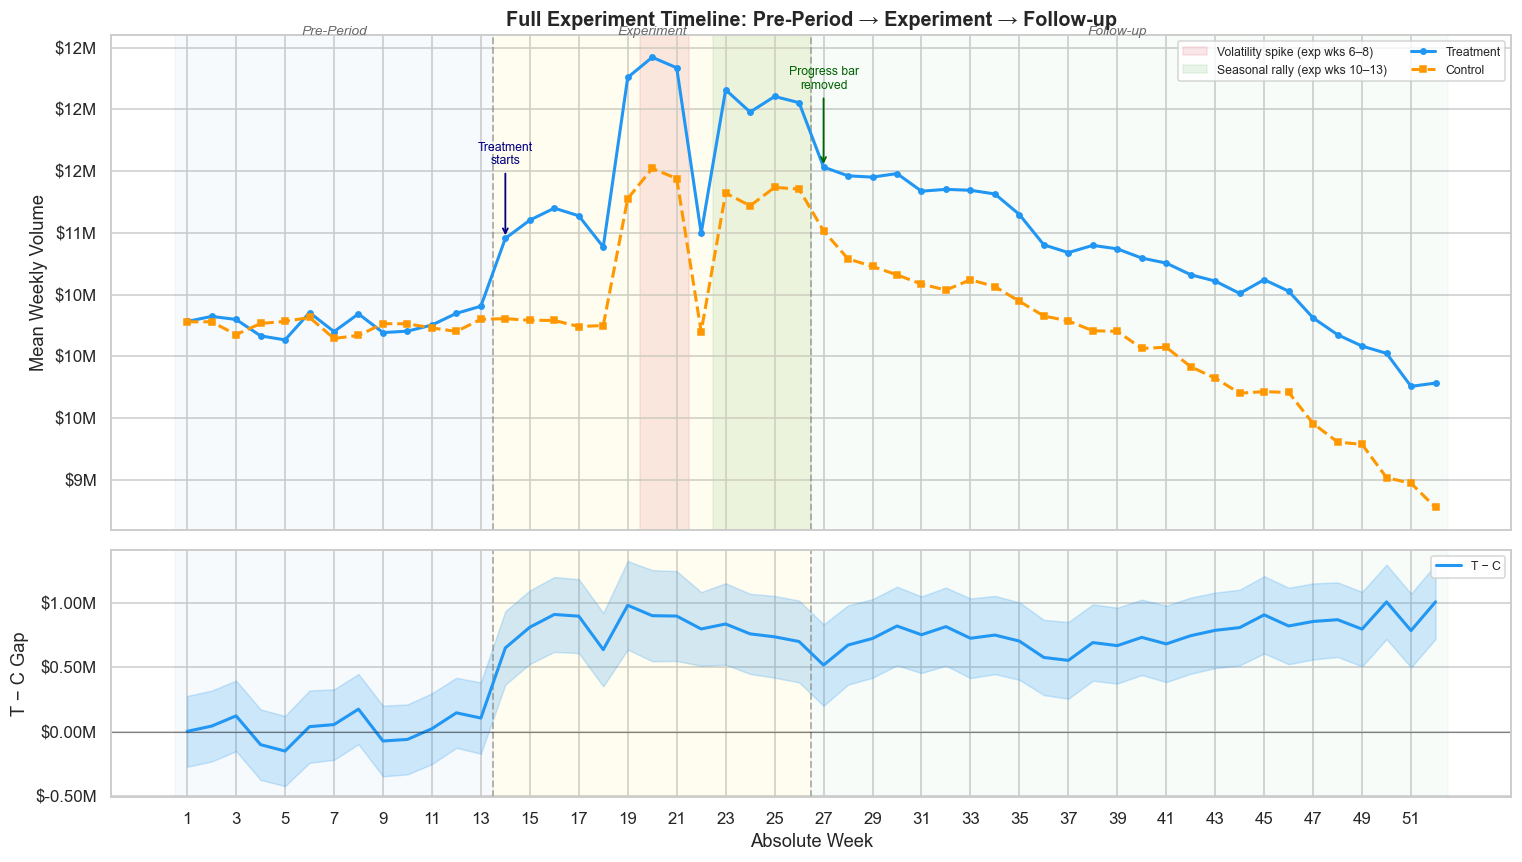

Avg gap — Pre: $+26K  |  Experiment: $+0.808M  |  Late follow-up: $+0.831M
Pre gap ≈ 0 (< $200K):                   ✓
Experiment gap > pre gap:                 ✓
Late follow-up gap > 0 (golden handcuff): ✓
Gap stable in follow-up (< 2× exp gap):  ✓


In [7]:
# Load followup (not loaded in setup cell)
followup = pd.read_csv(data_dir / "post_experiment_followup.csv")
followup = followup.merge(assignment[["client_id", "group"]], on="client_id")

# Assign absolute week numbers
pre["abs_week"]      = pre["week"]
post["abs_week"]     = post["week"] + 13
followup["abs_week"] = followup["week"] + 26

combined = pd.concat([
    pre[["abs_week", "group", "weekly_volume"]],
    post[["abs_week", "group", "weekly_volume"]],
    followup[["abs_week", "group", "weekly_volume"]],
], ignore_index=True)

# Compute weekly T/C means and SE
weekly = (
    combined.groupby(["abs_week", "group"])["weekly_volume"]
    .agg(["mean", "sem"])
    .reset_index()
)
t = weekly[weekly["group"] == "treatment"].set_index("abs_week")
c = weekly[weekly["group"] == "control"].set_index("abs_week")
abs_weeks = sorted(weekly["abs_week"].unique())

# ── 2-panel figure ──
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                                gridspec_kw={"height_ratios": [3, 1.5]})

# Period shading (both panels)
for ax in (ax1, ax2):
    ax.axvspan(0.5,  13.5, alpha=0.04, color="steelblue")
    ax.axvspan(13.5, 26.5, alpha=0.06, color="gold")
    ax.axvspan(26.5, 52.5, alpha=0.04, color="mediumseagreen")
    ax.axvline(13.5, color="grey", ls="--", lw=1.2, alpha=0.6)
    ax.axvline(26.5, color="grey", ls="--", lw=1.2, alpha=0.6)

# Confounder windows (experiment window only)
ax1.axvspan(19.5, 21.5, alpha=0.10, color="crimson", zorder=0, label="Volatility spike (exp wks 6–8)")
ax1.axvspan(22.5, 26.5, alpha=0.08, color="green",   zorder=0, label="Seasonal rally (exp wks 10–13)")

# Top panel: T and C lines
ax1.plot(abs_weeks, t.loc[abs_weeks, "mean"], "o-", color="#2196F3", lw=2, ms=3.5, label="Treatment")
ax1.plot(abs_weeks, c.loc[abs_weeks, "mean"], "s--", color="#FF9800", lw=2, ms=3.5, label="Control")

ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x/1e6:.0f}M"))
ax1.set_ylabel("Mean Weekly Volume")
ax1.set_title("Full Experiment Timeline: Pre-Period → Experiment → Follow-up",
              fontsize=13, fontweight="bold")
ax1.legend(fontsize=8, ncol=2)

# Period labels
for x, label in [(7, "Pre-Period"), (20, "Experiment"), (39, "Follow-up")]:
    ax1.text(x, t["mean"].max() * 1.015, label,
             ha="center", fontsize=9, color="dimgrey", style="italic")

# Key event annotations
ax1.annotate("Treatment\nstarts", xy=(14, t.loc[14, "mean"]),
             xytext=(14, t.loc[14, "mean"] * 1.055),
             arrowprops=dict(arrowstyle="->", color="navy", lw=1.2),
             fontsize=8, color="navy", ha="center")
ax1.annotate("Progress bar\nremoved", xy=(27, t.loc[27, "mean"]),
             xytext=(27, t.loc[27, "mean"] * 1.055),
             arrowprops=dict(arrowstyle="->", color="darkgreen", lw=1.2),
             fontsize=8, color="darkgreen", ha="center")

# Bottom panel: T−C gap with ±1 SE band
gap = t.loc[abs_weeks, "mean"].values - c.loc[abs_weeks, "mean"].values
se  = np.sqrt(t.loc[abs_weeks, "sem"].values**2 + c.loc[abs_weeks, "sem"].values**2)
ax2.fill_between(abs_weeks, gap - se, gap + se, alpha=0.2, color="#2196F3")
ax2.plot(abs_weeks, gap, "-", color="#2196F3", lw=2, label="T − C")
ax2.axhline(0, color="black", lw=0.8, alpha=0.4)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x/1e6:.2f}M"))
ax2.set_ylabel("T − C Gap")
ax2.set_xlabel("Absolute Week")
ax2.set_xticks(range(1, 53, 2))
ax2.legend(fontsize=8)

plt.tight_layout()
plt.show()

# Narrative checks
pre_gap  = gap[:13].mean()
exp_gap  = gap[13:26].mean()
late_gap = gap[39:].mean()   # last 13 weeks of follow-up
print(f"Avg gap — Pre: ${pre_gap/1e3:+.0f}K  |  "
      f"Experiment: ${exp_gap/1e6:+.3f}M  |  "
      f"Late follow-up: ${late_gap/1e6:+.3f}M")
print(f"Pre gap ≈ 0 (< $200K):                   {'✓' if abs(pre_gap) < 200_000 else '✗'}")
print(f"Experiment gap > pre gap:                 {'✓' if exp_gap > pre_gap + 200_000 else '✗'}")
print(f"Late follow-up gap > 0 (golden handcuff): {'✓' if late_gap > 0 else '✗ — full reversion, no tier retention'}")
# Exponential reversion: gap stays stable or narrows slightly; large growth = reversion_rate too low
print(f"Gap stable in follow-up (< 2× exp gap):  {'✓' if late_gap < 2 * exp_gap else '✗ — gap growing, check reversion_rate'}")